In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

clus = pd.read_csv('/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results_week2.csv')
print(clus.shape)
print(clus.columns.tolist())
clus.head()

(295616, 14)
['particle_id', 'x', 'y', 'Area', 'frame', 'cluster', 'cluster_size', 'particle_type', 'N_active', 'N_passive', 'active_fraction', 'cluster_num_AA_contacts', 'cluster_num_AP_contacts', 'cluster_num_PP_contacts']


,particle_id,x,y,Area,frame,cluster,cluster_size,particle_type,N_active,N_passive,active_fraction,cluster_num_AA_contacts,cluster_num_AP_contacts,cluster_num_PP_contacts
0,2,426.450,1012.742,120,1,2,6,passive,3,3,0.5,0,9,3
1,4,447.027,1013.581,74,1,2,6,active,3,3,0.5,0,9,3
2,5,1036.585,1014.553,94,1,5,5,active,3,2,0.6,0,4,1
3,6,1663.939,1013.535,57,1,6,4,active,2,2,0.5,0,3,1
4,10,405.876,1017.489,93,1,2,6,active,3,3,0.5,0,9,3


In [8]:
g = clus.groupby(['frame', 'cluster'])
clus['cm_x'] = g['x'].transform('mean')
clus['cm_y'] = g['y'].transform('mean')
clus[['frame', 'cluster', 'x', 'y', 'cm_x', 'cm_y']].head(10)
# grouping by cluster for every particle

,frame,cluster,x,y,cm_x,cm_y
0,1,2,426.450,1012.742,428.849167,1029.876833
1,1,2,447.027,1013.581,428.849167,1029.876833
2,1,5,1036.585,1014.553,1075.424600,1009.468800
3,1,6,1663.939,1013.535,1660.168250,1026.493750
4,1,2,405.876,1017.489,428.849167,1029.876833
5,1,5,1056.596,1003.013,1075.424600,1009.468800
6,1,5,1077.000,1002.500,1075.424600,1009.468800
7,1,6,1644.492,1007.897,1660.168250,1026.493750
8,1,5,1096.533,1006.475,1075.424600,1009.468800
9,1,48,1739.979,1038.953,1736.026000,1047.395250


In [7]:
clus['x_rel_CM'] = clus['x'] - clus['cm_x']
clus['y_rel_CM'] = clus['y'] - clus['cm_y']
clus[['x', 'cm_x', 'x_rel_CM', 'y', 'cm_y', 'y_rel_CM']].head(10)
#so for every particle we subtracted from its clusters avg x and stored that

,x,cm_x,x_rel_CM,y,cm_y,y_rel_CM
0,426.450,428.849167,-2.399167,1012.742,1029.876833,-17.134833
1,447.027,428.849167,18.177833,1013.581,1029.876833,-16.295833
2,1036.585,1075.424600,-38.839600,1014.553,1009.468800,5.084200
3,1663.939,1660.168250,3.770750,1013.535,1026.493750,-12.958750
4,405.876,428.849167,-22.973167,1017.489,1029.876833,-12.387833
5,1056.596,1075.424600,-18.828600,1003.013,1009.468800,-6.455800
6,1077.000,1075.424600,1.575400,1002.500,1009.468800,-6.968800
7,1644.492,1660.168250,-15.676250,1007.897,1026.493750,-18.596750
8,1096.533,1075.424600,21.108400,1006.475,1009.468800,-2.993800
9,1739.979,1736.026000,3.953000,1038.953,1047.395250,-8.442250


In [11]:
clus['dist_sq'] = clus['x_rel_CM']**2 + clus['y_rel_CM']**2
clus[['x_rel_CM', 'y_rel_CM', 'dist_sq']].head(10)
# Step 3 is to square each particle’s distance from the center. , so x^2 + y^2 for each particle

,x_rel_CM,y_rel_CM,dist_sq
0,-2.399167,-17.134833,299.358514
1,18.177833,-16.295833,595.987809
2,-38.839600,5.084200,1534.363618
3,3.770750,-12.958750,182.147757
4,-22.973167,-12.387833,681.224801
5,-18.828600,-6.455800,396.193532
6,1.575400,-6.968800,51.046059
7,-15.676250,-18.596750,591.583925
8,21.108400,-2.993800,454.527389
9,3.953000,-8.442250,86.897794


In [14]:
clus['mean_dist_sq'] = clus.groupby(['frame', 'cluster'])['dist_sq'].transform('mean')
clus[['frame', 'cluster', 'cluster_size', 'dist_sq', 'mean_dist_sq']].head(10)

# dist_sq is dist from mean x ^2 + dist from mean y ^ 2 
# so for every cluster, we add the dist_sq for all particles and divide by num of particles

,frame,cluster,cluster_size,dist_sq,mean_dist_sq
0,1,2,6,299.358514,493.139937
1,1,2,6,595.987809,493.139937
2,1,5,5,1534.363618,757.700586
3,1,6,4,182.147757,390.941106
4,1,2,6,681.224801,493.139937
5,1,5,5,396.193532,757.700586
6,1,5,5,51.046059,757.700586
7,1,6,4,591.583925,390.941106
8,1,5,5,454.527389,757.700586
9,1,48,4,86.897794,325.396135


In [16]:
clus['Rg_px'] = np.sqrt(clus['mean_dist_sq'])
clus[['frame', 'cluster', 'cluster_size', 'mean_dist_sq', 'Rg_px']].head(10)
#dist_sq = (x − mean x)² + (y − mean y)², for each particle.
# mean_dist_sq = the sum of dist_sq over the cluster ÷ the number of particles.
# Rg_px = √mean_dist_sq. <- this is what we did now, sqaure rooting gives us the radius of gyration in pixels

,frame,cluster,cluster_size,mean_dist_sq,Rg_px
0,1,2,6,493.139937,22.206754
1,1,2,6,493.139937,22.206754
2,1,5,5,757.700586,27.526362
3,1,6,4,390.941106,19.772231
4,1,2,6,493.139937,22.206754
5,1,5,5,757.700586,27.526362
6,1,5,5,757.700586,27.526362
7,1,6,4,390.941106,19.772231
8,1,5,5,757.700586,27.526362
9,1,48,4,325.396135,18.038740


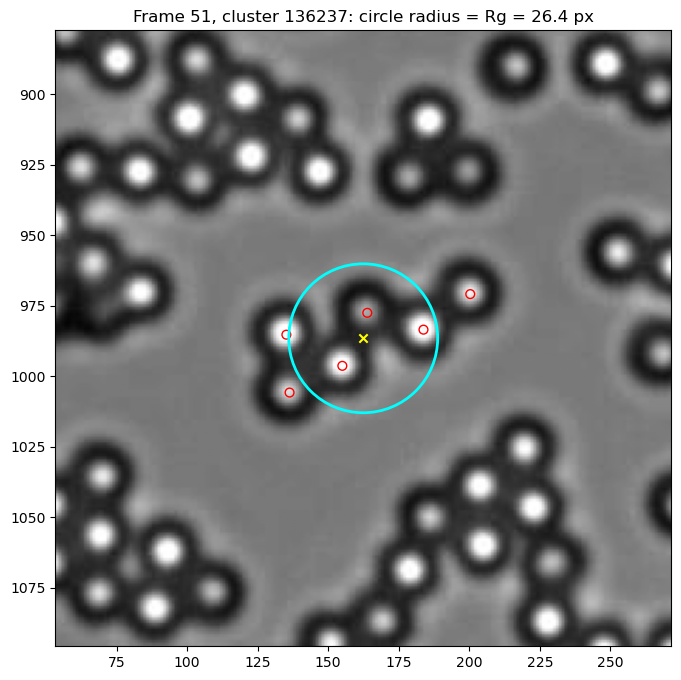

In [18]:
FRAME = 51
IMG = '/Users/rayyan/Desktop/honors_indep_study/0.07 s.png'
CL = clus[clus['frame'] == FRAME]['cluster'].iloc[0]   # first cluster in this frame

c = clus[(clus['frame'] == FRAME) & (clus['cluster'] == CL)]
cx, cy, rg = c['cm_x'].iloc[0], c['cm_y'].iloc[0], c['Rg_px'].iloc[0]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(plt.imread(IMG), cmap='gray')
ax.scatter(c['x'], c['y'], s=40, facecolors='none', edgecolors='red')   # particles
ax.scatter(cx, cy, marker='x', color='yellow')                            # center
ax.add_patch(Circle((cx, cy), rg, fill=False, edgecolor='cyan', linewidth=2))

pad = 3 * rg + 30                          # zoom in around the cluster
ax.set_xlim(cx - pad, cx + pad)
ax.set_ylim(cy + pad, cy - pad)            # flipped so y runs downward like the image
ax.set_title(f'Frame {FRAME}, cluster {CL}: circle radius = Rg = {rg:.1f} px')
plt.show()

#checking by circling a cluster using the radius of gyration

In [19]:
clus = clus.drop(columns=['dist_sq', 'mean_dist_sq'], errors='ignore')   # temporary columns

OUT = '/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results_week3.csv'
clus.to_csv(OUT, index=False)
print("saved:", OUT, clus.shape)
print(clus.columns.tolist())

saved: /Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results_week3.csv (295616, 19)
['particle_id', 'x', 'y', 'Area', 'frame', 'cluster', 'cluster_size', 'particle_type', 'N_active', 'N_passive', 'active_fraction', 'cluster_num_AA_contacts', 'cluster_num_AP_contacts', 'cluster_num_PP_contacts', 'cm_x', 'cm_y', 'x_rel_CM', 'y_rel_CM', 'Rg_px']
